<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/advanced_cnn_models/11_PAN_ResNet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains the complete training log and evaluation output for PAN_ResNet50 on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.

In [ ]:
# Install dependencies
!pip install -q webdataset segmentation-models-pytorch albumentations

# Imports
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import numpy as np
import torch
import torch.nn as nn
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import random
import warnings
warnings.filterwarnings("ignore")

print("✅ PAN ResNet50 Training Ready!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 11.1 MB/s eta 0:00:00
Mounted at /content/drive
✅ PAN ResNet50 Training Ready!


In [ ]:
drive_dataset_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/WebDataset/snow_patches_5000_random.tar"
colab_dataset_path = "/tmp/snow_patches_5000_random.tar"

os.makedirs(os.path.dirname(colab_dataset_path), exist_ok=True)
print("📥 Copying dataset...")
shutil.copy(drive_dataset_path, colab_dataset_path)
print(f"✅ Dataset: {os.path.getsize(colab_dataset_path)/1024**3:.2f} GB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Device: {device}")
wds_path = colab_dataset_path

📥 Copying dataset...
✅ Dataset: 0.41 GB
🚀 Device: cuda


In [ ]:
MODEL_NAME = "PAN_ResNet50"
final_results_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results"
model_results_path = os.path.join(final_results_path, MODEL_NAME)

os.makedirs(model_results_path, exist_ok=True)
print(f"📁 Results: {model_results_path}")

📁 Results: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/PAN_ResNet50


In [ ]:
CONFIG = {
    "model_name": MODEL_NAME,
    "encoder_name": "resnet50",
    "num_epochs": 50,
    "batch_size": 16,
    "learning_rate": 1e-4,
    "num_workers": 0,
    "total_patches": 5000
}

CONFIG["train_size"] = int(CONFIG["total_patches"] * 0.7)
CONFIG["val_size"] = int(CONFIG["total_patches"] * 0.2)
CONFIG["test_size"] = CONFIG["total_patches"] - CONFIG["train_size"] - CONFIG["val_size"]

train_batches = CONFIG["train_size"] // CONFIG["batch_size"]
val_batches = CONFIG["val_size"] // CONFIG["batch_size"]

print(f"📊 Train/Val/Test: {CONFIG['train_size']}/{CONFIG['val_size']}/{CONFIG['test_size']}")

📊 Train/Val/Test: 3500/1000/500


In [ ]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

def preprocess_sample(sample, transform):
    img = np.array(sample["image.png"].convert("RGB"))
    msk = np.array(sample["mask.png"].convert("L")) / 255.0
    t = transform(image=img, mask=msk)
    return t["image"], t["mask"].unsqueeze(0)

In [ ]:
train_dataset = (wds.WebDataset(wds_path)
    .shuffle(1000).decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG["batch_size"]))

val_dataset = (wds.WebDataset(wds_path)
    .decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG["batch_size"]))

train_loader = wds.WebLoader(train_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(train_batches)
val_loader = wds.WebLoader(val_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(val_batches)

print("✅ Data loaders ready!")

✅ Data loaders ready!


In [ ]:
print(f"🔨 Building PAN ({CONFIG['encoder_name']} + ImageNet)...")

model = smp.PAN(
    encoder_name=CONFIG["encoder_name"],
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"✅ PAN Model ready!")
print(f"📈 Parameters: {total_params:,}")

🔨 Building PAN (resnet50 + ImageNet)...


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

✅ PAN Model ready!
📈 Parameters: 24,259,816


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self): super().__init__(); self.bce = nn.BCEWithLogitsLoss()
    def forward(self, pred, target):
        bce = self.bce(pred, target)
        p = torch.sigmoid(pred)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + 1e-6) / (p.sum() + target.sum() + 1e-6)
        return 0.5 * bce + 0.5 * dice

def calc_iou(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + 1e-6) / (union + 1e-6)

def calc_dice(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    return (2 * inter + 1e-6) / (pred.sum() + target.sum() + 1e-6)

def calc_precision(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (pred.sum() + 1e-6)

def calc_recall(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (target.sum() + 1e-6)

criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=5, factor=0.5)

history = {"train_loss":[], "val_loss":[], "train_iou":[], "val_iou":[],
           "train_dice":[], "val_dice":[], "train_precision":[], "val_precision":[],
           "train_recall":[], "val_recall":[], "learning_rate":[]}

best_dice = 0.0

In [ ]:
def train_epoch(model, loader, num_batches):
    model.train()
    losses, ious, dices, precs, recs = [], [], [], [], []
    pbar = tqdm(enumerate(loader), total=num_batches, desc="Train")
    for bi, (imgs, msks) in pbar:
        if bi >= num_batches: break
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, msks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        losses.append(loss.item())
        ious.append(calc_iou(preds, msks).item())
        dices.append(calc_dice(preds, msks).item())
        precs.append(calc_precision(preds, msks).item())
        recs.append(calc_recall(preds, msks).item())
        pbar.set_postfix(loss=f"{np.mean(losses):.4f}", dice=f"{np.mean(dices):.4f}")
    return {"loss": np.mean(losses), "iou": np.mean(ious), "dice": np.mean(dices),
            "precision": np.mean(precs), "recall": np.mean(recs)}

def val_epoch(model, loader, num_batches):
    model.eval()
    losses, ious, dices, precs, recs = [], [], [], [], []
    with torch.no_grad():
        pbar = tqdm(enumerate(loader), total=num_batches, desc="Val")
        for bi, (imgs, msks) in pbar:
            if bi >= num_batches: break
            imgs, msks = imgs.to(device), msks.to(device)
            preds = model(imgs)
            loss = criterion(preds, msks)
            losses.append(loss.item())
            ious.append(calc_iou(preds, msks).item())
            dices.append(calc_dice(preds, msks).item())
            precs.append(calc_precision(preds, msks).item())
            recs.append(calc_recall(preds, msks).item())
            pbar.set_postfix(loss=f"{np.mean(losses):.4f}", dice=f"{np.mean(dices):.4f}")
    return {"loss": np.mean(losses), "iou": np.mean(ious), "dice": np.mean(dices),
            "precision": np.mean(precs), "recall": np.mean(recs)}

In [ ]:
print("="*80)
print(f"🚀 {MODEL_NAME} TRAINING START")
print("="*80)

for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['num_epochs']}")

    train_m = train_epoch(model, train_loader, train_batches)
    val_m = val_epoch(model, val_loader, val_batches)

    val_loss = val_m["loss"]
    scheduler.step(val_loss)
    lr = optimizer.param_groups[0]["lr"]

    for k in ["loss", "iou", "dice", "precision", "recall"]:
        history[f"train_{k}"].append(train_m[k])
        history[f"val_{k}"].append(val_m[k])
    history["learning_rate"].append(lr)

    print(f"LR: {lr:.2e} | Train Dice: {train_m['dice']:.4f} | Val Dice: {val_m['dice']:.4f}")

    if val_m["dice"] > best_dice:
        best_dice = val_m["dice"]
        torch.save(model.state_dict(), os.path.join(model_results_path, "best_model.pth"))
        print(f"  ⭐ NEW BEST: {best_dice:.4f}")

🚀 PAN_ResNet50 TRAINING START

Epoch 1/50


Val: 100%|██████████| 62/62 [00:11<00:00,  5.64it/s, dice=0.8766, loss=0.1838]


LR: 1.00e-04 | Train Dice: 0.7408 | Val Dice: 0.8766
  ⭐ NEW BEST: 0.8766

Epoch 2/50


Val: 100%|██████████| 62/62 [00:11<00:00,  5.51it/s, dice=0.8947, loss=0.1626]


LR: 1.00e-04 | Train Dice: 0.7714 | Val Dice: 0.8947
  ⭐ NEW BEST: 0.8947

Epoch 3/50


Val: 100%|██████████| 62/62 [00:10<00:00,  5.83it/s, dice=0.9001, loss=0.1418]


... (91 outputs left out)

Val: 100%|██████████| 62/62 [00:11<00:00,  5.63it/s, dice=0.9224, loss=0.1110]


LR: 1.00e-04 | Train Dice: 0.8431 | Val Dice: 0.9224

Epoch 50/50


Val: 100%|██████████| 62/62 [00:10<00:00,  5.68it/s, dice=0.9232, loss=0.1095]


LR: 1.00e-04 | Train Dice: 0.8409 | Val Dice: 0.9232
  ⭐ NEW BEST: 0.9232


In [ ]:
torch.save(model.state_dict(), os.path.join(model_results_path, "final_model.pth"))
pd.DataFrame(history).to_csv(os.path.join(model_results_path, "training_history.csv"), index=False)

print("✅ SAVED TO:", model_results_path)

✅ SAVED TO: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/PAN_ResNet50


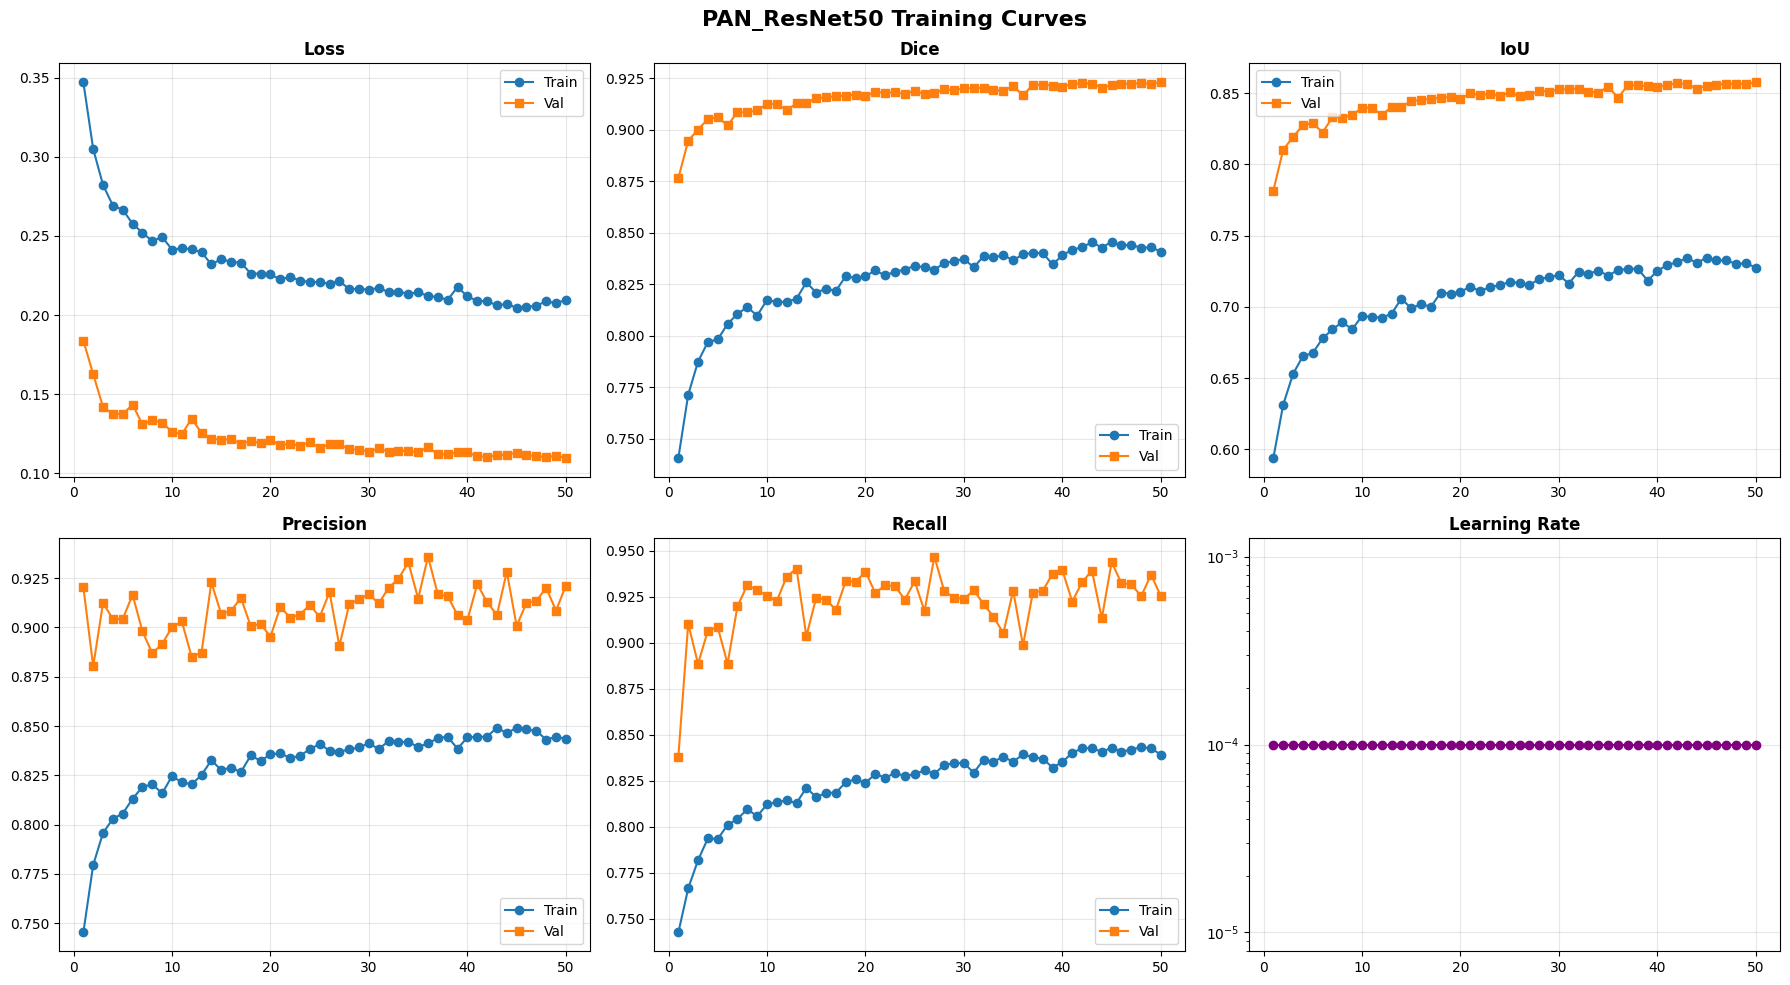

In [ ]:
epochs = np.arange(1, CONFIG["num_epochs"] + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics = [("train_loss", "val_loss", "Loss"), ("train_dice", "val_dice", "Dice"), ("train_iou", "val_iou", "IoU")]
for i, (tr, vl, title) in enumerate(metrics):
    axes[0, i].plot(epochs, history[tr], "o-", label="Train")
    axes[0, i].plot(epochs, history[vl], "s-", label="Val")
    axes[0, i].set_title(title, fontweight="bold")
    axes[0, i].legend(); axes[0, i].grid(alpha=0.3)

axes[1, 0].plot(epochs, history["train_precision"], "o-", label="Train")
axes[1, 0].plot(epochs, history["val_precision"], "s-", label="Val")
axes[1, 0].set_title("Precision", fontweight="bold"); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(epochs, history["train_recall"], "o-", label="Train")
axes[1, 1].plot(epochs, history["val_recall"], "s-", label="Val")
axes[1, 1].set_title("Recall", fontweight="bold"); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

axes[1, 2].plot(epochs, history["learning_rate"], "o-", color="purple")
axes[1, 2].set_title("Learning Rate", fontweight="bold"); axes[1, 2].set_yscale("log"); axes[1, 2].grid(alpha=0.3)

plt.suptitle(f"{MODEL_NAME} Training Curves", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "training_curves.png"), dpi=300)
plt.show()

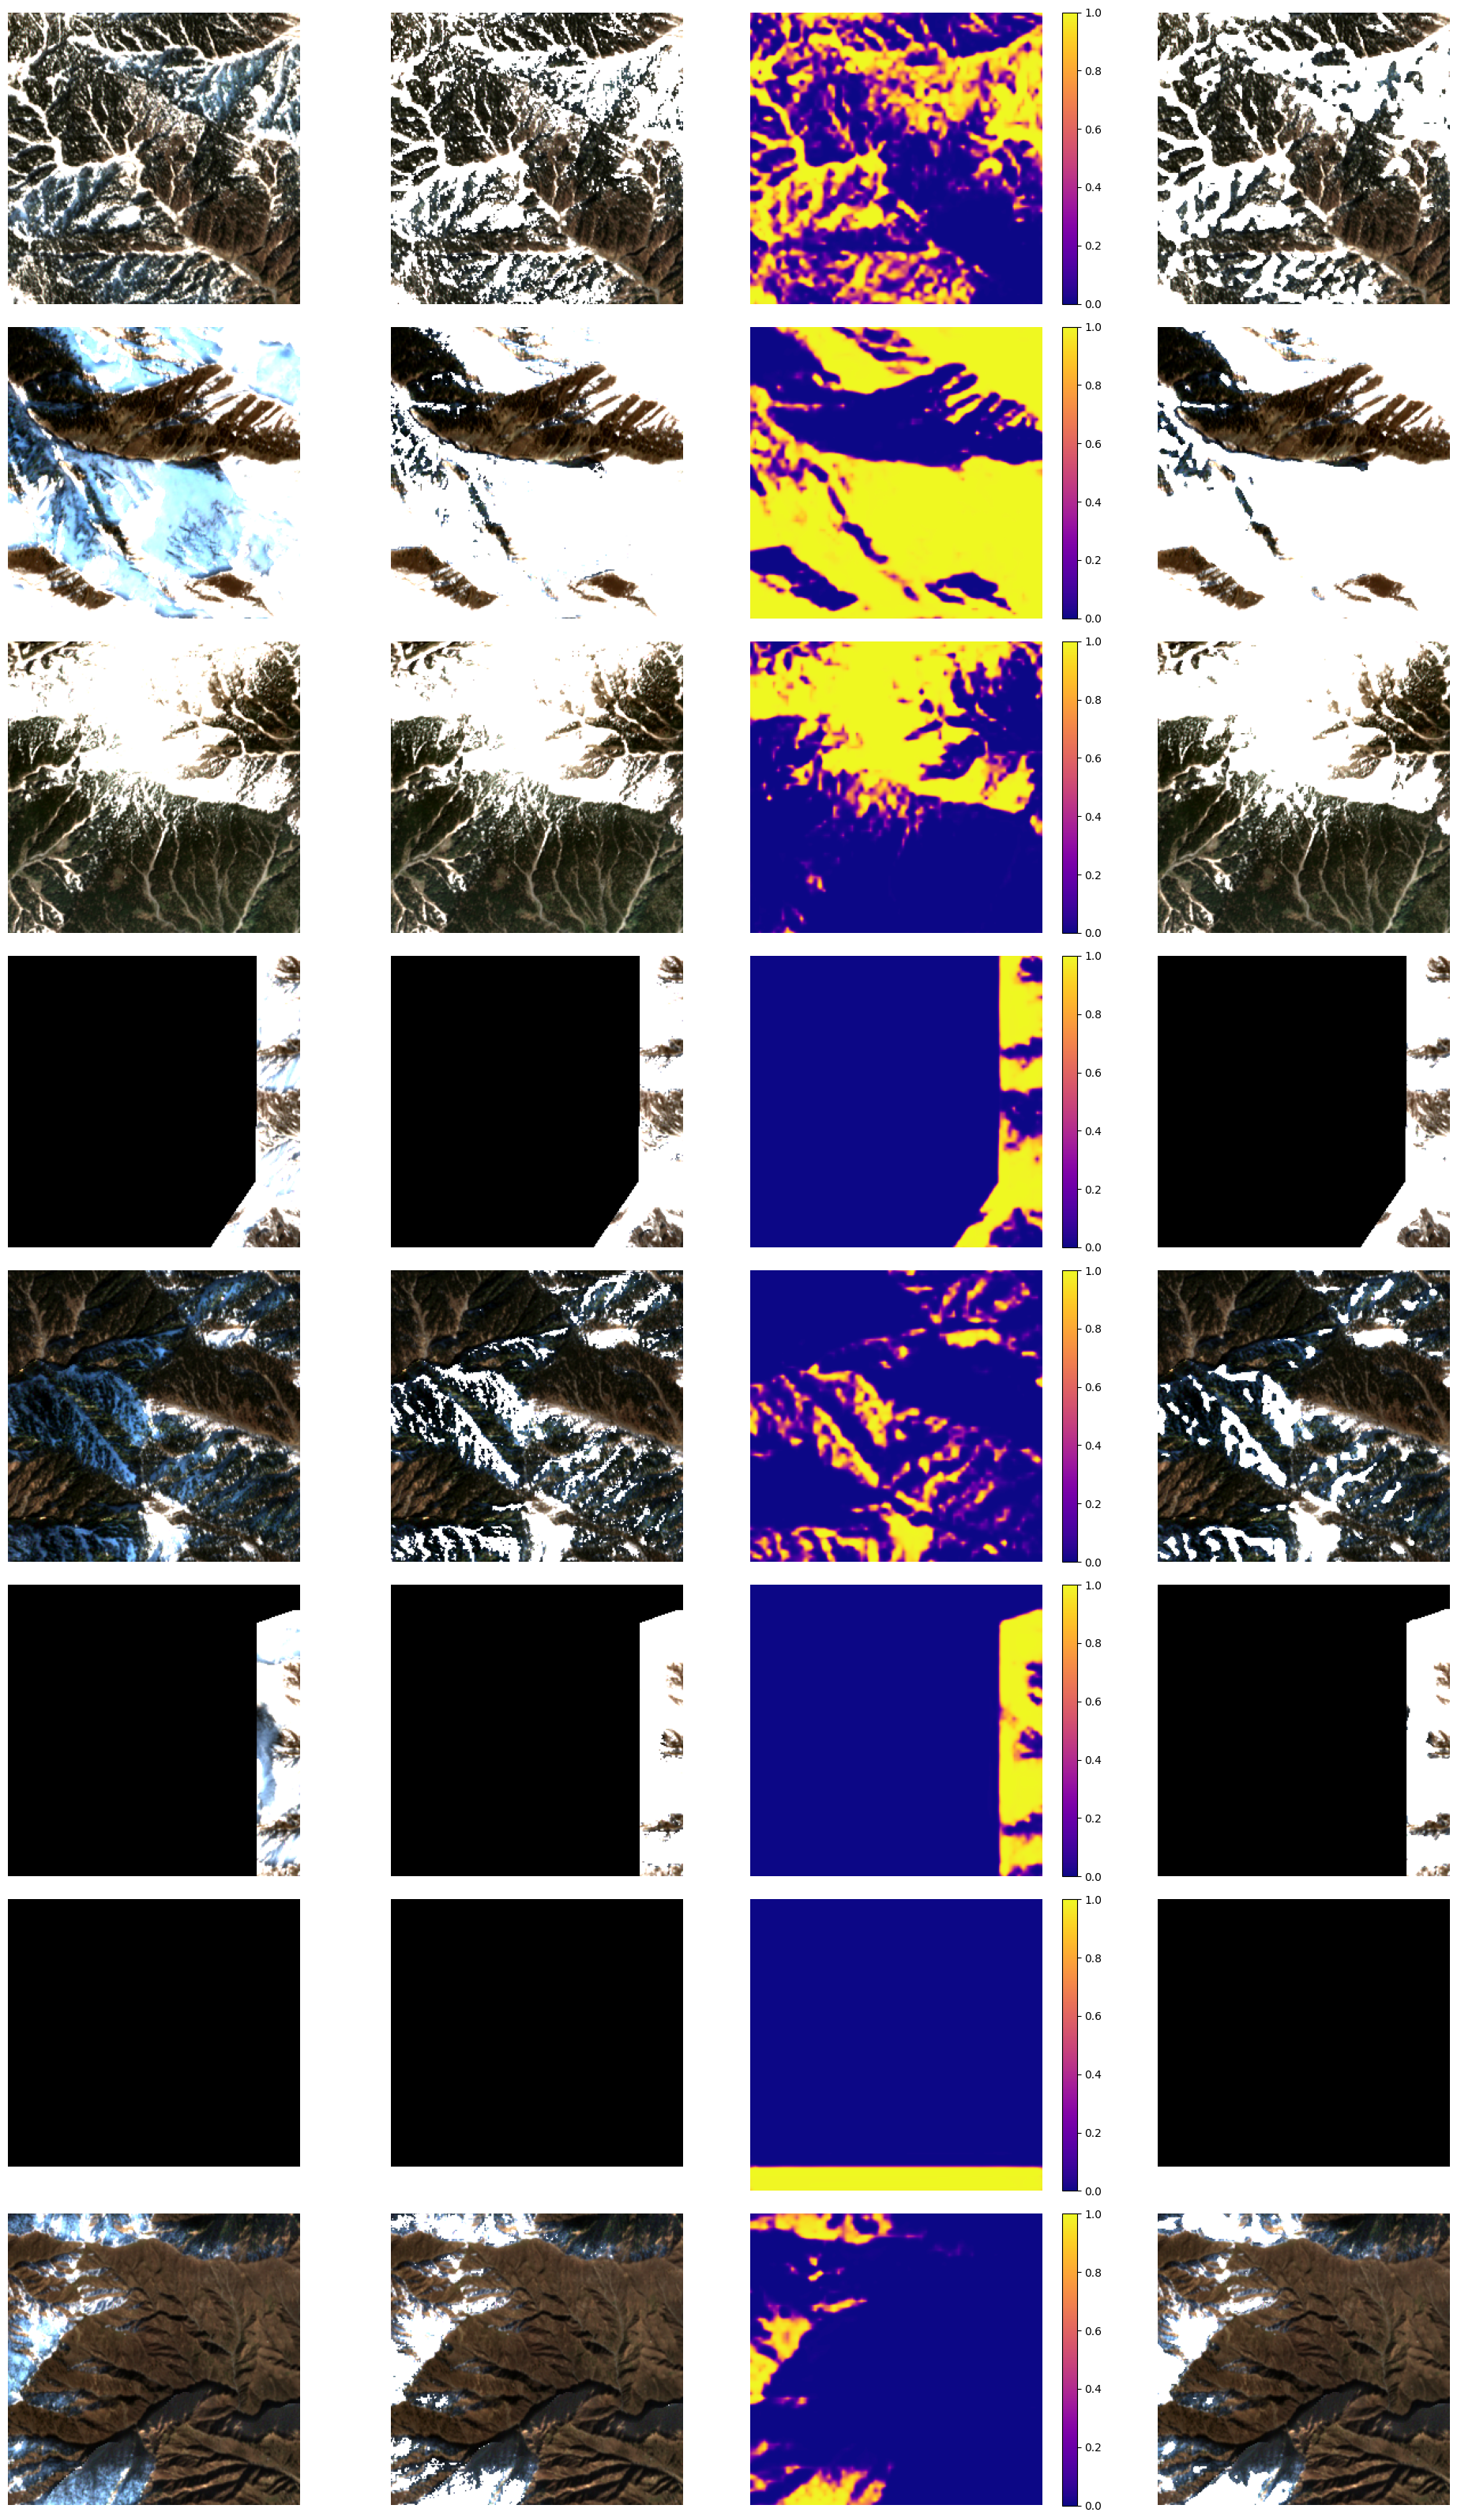

In [ ]:
import matplotlib.patches as mpatches

best_model_path = os.path.join(model_results_path, "best_model.pth")
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

raw_ds = wds.WebDataset(wds_path).decode("pil").to_tuple("image.png", "mask.png")
all_samples = list(raw_ds)
random.seed(42)
num_samples = 8
test_indices = random.sample(range(CONFIG["train_size"] + CONFIG["val_size"], len(all_samples)), num_samples)

fig, axes = plt.subplots(num_samples, 4, figsize=(20, 4*num_samples))

with torch.no_grad():
    for i, idx in enumerate(test_indices):
        img_pil, mask_pil = all_samples[idx]
        img_np = np.array(img_pil.convert("RGB"))
        mask_np = (np.array(mask_pil.convert("L")) / 255.0).astype(np.float32)

        t = val_transform(image=img_np, mask=mask_np)
        img_t = t["image"].unsqueeze(0).to(device)
        pred_prob = torch.sigmoid(model(img_t)).squeeze().cpu().numpy()

        d = calc_dice(torch.from_numpy(pred_prob).unsqueeze(0).unsqueeze(0), torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0)).item()
        j = calc_iou(torch.from_numpy(pred_prob).unsqueeze(0).unsqueeze(0), torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0)).item()

        pred_overlay, gt_overlay = img_np.copy(), img_np.copy()
        pred_overlay[pred_prob > 0.5] = 255
        gt_overlay[mask_np > 0.5] = 255

        axes[i, 0].imshow(img_np); axes[i, 0].axis("off")
        axes[i, 1].imshow(gt_overlay); axes[i, 1].axis("off")
        im = axes[i, 2].imshow(pred_prob, cmap="plasma", vmin=0, vmax=1); axes[i, 2].axis("off")
        plt.colorbar(im, ax=axes[i, 2])
        axes[i, 3].imshow(pred_overlay); axes[i, 3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "test_predictions_white_snow.png"), dpi=300)
plt.show()